# Семинар 2

**Данные:** PBMC 3k (периферическая кровь человека, 10x Genomics)

В первом семинаре мы получили матрицу экспрессии, провели QC, нормализацию, выбрали 2000 высоковариабельных генов (HVG) и построили PCA. Теперь мы хотим ответить на два разных вопроса:

1. **Какие клетки образуют группы?** Для этого строим граф ближайших соседей и применяем Leiden.
2. **Как показать тысячи клеток на одном двумерном графике?** Для этого используем UMAP или t-SNE.

> **Главное различие:** Leiden определяет кластеры **на графе соседства**, построенном по координатам PCA. UMAP и t-SNE нужны прежде всего для **визуализации**, а не для установления кластеров.

## 0. Подготовка окружения

Можно продолжить работу в окружении `sc_pbmc` из первого семинара. Для Leiden нужны **`leidenalg` и `python-igraph`**

```bash
mamba create -n sc_pbmc -c conda-forge \
    python=3.11 "scanpy>=1.11,<2" scikit-misc leidenalg python-igraph \
    umap-learn scikit-learn pandas numpy scipy matplotlib \
    jupyterlab ipykernel -y
mamba activate sc_pbmc
python -m ipykernel install --user --name sc_pbmc --display-name "sc_pbmc"
```

Если окружение уже создано, достаточно:

```bash
mamba activate sc_pbmc
mamba install -c conda-forge leidenalg python-igraph umap-learn scikit-learn -y
```


In [13]:
!pip install scanpy leidenalg igraph scikit-misc umap-learn -q

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.


In [14]:
from pathlib import Path
import scanpy as sc
import leidenalg
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


## 0.1. Продолжаем первый семинар на тех же данных PBMC 3k

- Если `data/pbmc3k_after_pca.h5ad` уже существует, загрузим готовую обработанную матрицу.
- Иначе прочитаем исходную матрицу из `data/filtered_gene_bc_matrices/hg19/` (папка из предыдущего занятия). Если её нет, Scanpy скачает PBMC 3k из своей коллекции данных и мы повторим **те же** пороги QC, HVG и PCA.

Исходные данные: [10x Genomics PBMC 3k](https://www.10xgenomics.com/datasets/3-k-pbm-cs-from-a-healthy-donor-1-standard-1-0-0). Функция загрузки: [`sc.datasets.pbmc3k`](https://scanpy.readthedocs.io/en/stable/generated/scanpy.datasets.pbmc3k.html).

In [15]:
cache = Path("data/pbmc3k_after_pca.h5ad")
raw_folder = Path("data/filtered_gene_bc_matrices/hg19")


#adata = sc.read_10x_mtx(raw_folder, var_names="gene_symbols", make_unique=True)

adata = sc.datasets.pbmc3k()

  0%|                                              | 0.00/5.86M [00:00<?, ?B/s]

In [16]:
 adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

In [17]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
adata = adata[
    (adata.obs["n_genes_by_counts"] < 2500) &
    (adata.obs["pct_counts_mt"] < 5)
].copy()


/tmp/ipykernel_1907/2689764218.py:2: FutureWarning: The argument inplace is deprecated and will be removed in the future. Use `out=False` instead of `inplace=True`.
  sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)


In [18]:
adata.layers["counts"] = adata.X.copy()

In [19]:
sc.pp.highly_variable_genes(
    adata, layer="counts", flavor="seurat_v3", n_top_genes=2000
)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.tl.pca(adata, n_comps=50, mask_var="highly_variable", random_state=42)

/tmp/ipykernel_1907/2512409476.py:1: FutureWarning: The argument layer is deprecated and will be removed in the future. Use `use` instead.
  sc.pp.highly_variable_genes(
/tmp/ipykernel_1907/2512409476.py:6: FutureWarning: The argument mask_var is deprecated and will be removed in the future. Use `mask` instead.
  sc.tl.pca(adata, n_comps=50, mask_var="highly_variable", random_state=42)


In [20]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'counts'

# 1. Повторение PCA

В первом семинаре каждой клетке сопоставили вектор экспрессии генов. PCA заменяет исходные признаки координатами в новом базисе:

$$
\mathbf{x}_i=(PC_{i1},PC_{i2},\dots,PC_{ip})\in\mathbb{R}^{p}.
$$

В `adata.obsm["X_pca"]` каждая **строка соответствует клетке**, каждый **столбец — компоненте PCA**.

Евклидово расстояние между клетками $i$ и $j$ в пространстве первых $p$ компонент:

$$
d(i,j)=\left\|\mathbf{x}_i-\mathbf{x}_j\right\|_2
=\sqrt{\sum_{r=1}^{p}\left(PC_{ir}-PC_{jr}\right)^2}.
$$


In [21]:
X_pca = adata.obsm["X_pca"]
print("Первые 5 клеток, первые 5 координат PCA:")
display(pd.DataFrame(X_pca[:5, :5], index=adata.obs_names[:5],
                     columns=[f"PC{i}" for i in range(1, 6)]))

Первые 5 клеток, первые 5 координат PCA:


,PC1,PC2,PC3,PC4,PC5
index,,,,,
AAACATACAACCAC-1,-4.729656,-0.732485,-1.319631,0.310005,-0.847269
AAACATTGAGCTAC-1,-0.771727,7.029477,4.317773,-1.829984,-1.793581
AAACATTGATCAGC-1,-3.747784,-2.741884,-2.263518,-3.970395,-1.300419
AAACCGTGCTTCCG-1,13.714365,0.483030,1.592937,-0.528195,1.163329
AAACCGTGTATGCG-1,-3.042009,-4.998953,7.369839,5.631863,1.837182


# 2. От точек к графу: kNN

**Граф** — это набор вершин и рёбер. В нашей задаче:

- вершина = одна клетка;
- ребро $i\to j$ = клетка $j$ входит в число $k$ ближайших соседей клетки $i$;
- вес ребра = численная оценка близости клеток.

Сначала алгоритм ищет **kNN — k nearest neighbors**. Это отношение в общем случае **направленное**: клетка B может входить в 2 ближайших соседа A, но клетка A может не входить в 2 ближайших соседа B.

Для графовой кластеризации обычно используют **ненаправленный взвешенный граф**. Простейшая симметризация бинарного графа — $A_{ij}^{\mathrm{sym}}=\max(A_{ij},A_{ji})$.

В Scanpy при `method="umap"` расчёт **весов** устроен сложнее: используются локально масштабированные степени принадлежности к соседству с последующим объединением направленных связей. Это **не** просто обратное евклидово расстояние.


### kNN на реальных клетках

В Scanpy используется **двухэтапная процедура**:

1. Найти ближайших соседей по координатам первых 30 PC (`n_pcs=30`).
2. По этим соседям вычислить веса связей между клетками (`connectivities`).

**Где хранятся результаты?**

| Поле AnnData | Что означает |
|---|---|
| `adata.obsm["X_pca"]` | Координаты клеток в PCA |
| `adata.obsp["distances"]` | Разреженная матрица найденных расстояний |
| `adata.obsp["connectivities"]` | Разреженная, симметричная матрица весов связей |
| `adata.uns["neighbors"]` | Параметры построения графа и ссылки на матрицы |

**Важно:** `n_neighbors=15` — локальный параметр поиска соседей. После симметризации у вершины может оказаться **больше 15 ненулевых связей**.

In [22]:
sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=30,
    metric="euclidean",
    method="umap",
    random_state=42,
)

In [23]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca', 'neighbors'
    obsm: 'X_pca'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'
    layers: None (.X), 'counts'

In [24]:
G = adata.obsp["connectivities"].tocsr()
D = adata.obsp["distances"].tocsr()

In [25]:
print("Граф connectivities:", G.shape, "ненулевых элементов:", G.nnz)

print("Матрица distances:", D.shape, "ненулевых элементов:", D.nnz)

Граф connectivities: (2638, 2638) ненулевых элементов: 58162
Матрица distances: (2638, 2638) ненулевых элементов: 36932


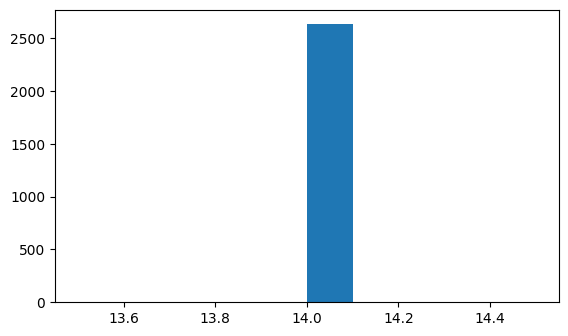

Минимум / медиана / максимум степеней: 14 14.0 14


In [26]:
degree = np.asarray((D > 0).sum(axis=1)).ravel()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.hist(degree, bins=10)
plt.show()

print("Минимум / медиана / максимум степеней:",
      degree.min(), np.median(degree), degree.max())

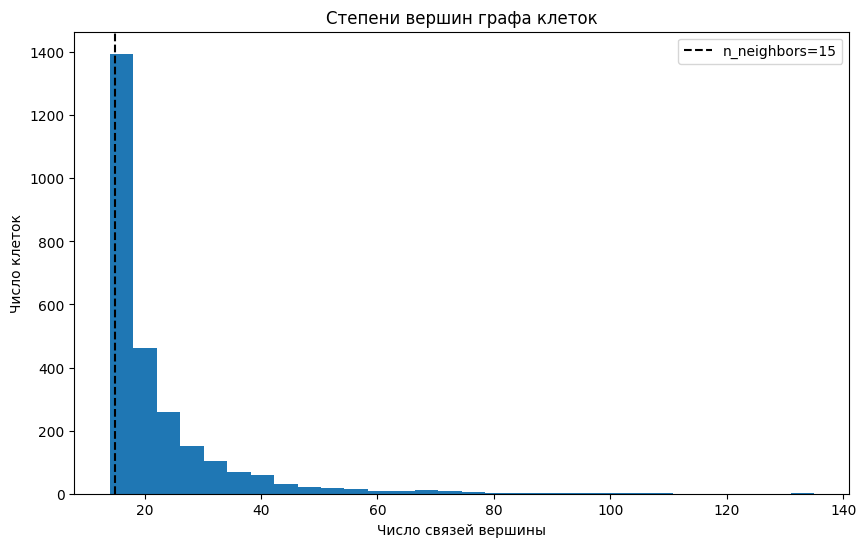

Число компонент связности: 1
Минимум / медиана / максимум степеней: 14 18.0 135


In [28]:
from scipy.sparse.csgraph import connected_components
degree = np.asarray((G > 0).sum(axis=1)).ravel()
components, labels_components = connected_components(G, directed=False)
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(degree, bins=30)
ax.axvline(15, ls="--", color="black", label="n_neighbors=15")
ax.set(xlabel="Число связей вершины", ylabel="Число клеток",
       title="Степени вершин графа клеток")
ax.legend()
plt.show()
print("Число компонент связности:", components)
print("Минимум / медиана / максимум степеней:",
      degree.min(), np.median(degree), degree.max())

# 3. Графовая кластеризация: Louvain → Leiden

**Кластеризация** — разбиение объектов на группы. Но «хорошая группа» должна иметь математическое определение.

- В методах типа k-means группа — набор точек, близких к общему центроиду.
- В графовых методах **сообщество** — группа вершин, которые связаны друг с другом сильнее, чем ожидалось бы при случайном соединении вершин по подходящей нулевой модели.

## 3.1. Модулярность: что оптимизирует алгоритм

Рассмотрим **ненаправленный граф** с матрицей весов $A=(A_{ij})$. Обозначим:

- $A_{ij}$ — вес ребра между вершинами $i$ и $j$;
- $k_i=\sum_j A_{ij}$ — взвешенная степень вершины $i$;
- $2m=\sum_i k_i$ — сумма весов рёбер, посчитанных по двум концам;
- $c_i$ — номер сообщества вершины $i$;
- $\mathbf{1}(c_i=c_j)$ равен единице, когда вершины в одной группе.

Одна из функций качества разбиения — **модулярность с параметром разрешения $\gamma$**:

$$
Q_{\gamma}=\frac{1}{2m}\sum_{i,j}
\left(A_{ij}-\gamma\frac{k_i k_j}{2m}\right)
\mathbf{1}(c_i=c_j).
$$

**Как понимать формулу:**

- $A_{ij}$ — наблюдаемый вес связи;
- $k_i k_j/(2m)$ — ожидаемый вес связи в модели случайного графа, сохраняющей ожидаемые степени вершин;
- в сумму попадают только пары вершин **из одной группы**;
- алгоритм пытается найти разбиение с **высоким значением $Q_\gamma$**.

$\gamma$ отвечает за масштаб: при большем $\gamma$ крупные сообщества сильнее «штрафуются», поэтому на практике часто появляются более мелкие кластеры. **Но число кластеров не обязано расти строго монотонно** из-за устройства графа и эвристической оптимизации.

## 3.2. Louvain и Leiden: чем они отличаются

**Louvain (2008):**

1. Стартует с отдельных сообществ (каждая вершина сама по себе).
2. По очереди переносит вершины между соседними сообществами, если растёт функция качества.
3. Объединяет сообщества в новые супервершины и повторяет оптимизацию.

**Проблема:** в отдельных случаях найденное сообщество может иметь плохую внутреннюю связность или даже быть несвязным.

**Leiden (2019)** добавляет **этап уточнения (refinement)** сообщества до агрегации. В результате алгоритм устраняет известную проблему несвязных сообществ Louvain и при сходимости предоставляет более сильные гарантии внутренней связности. Это **не означает**, что любой кластер Leiden биологически однороден.


Статья: [Traag, Waltman & van Eck, 2019 — From Louvain to Leiden](https://doi.org/10.1038/s41598-019-41695-z).

## 3.3. Leiden на PBMC 3k

Запустим Leiden несколько раз на **одном и том же графе**. Вызовы не используют координаты UMAP.

/tmp/ipykernel_1907/1703150331.py:1: FutureWarning: The argument key_added is deprecated and will be removed in the future. Use `out` instead.
  sc.tl.leiden(adata, resolution=0.2, key_added="leiden_0.2")
/usr/local/lib/python3.13/dist-packages/scverse_misc/_deprecated/__init__.py:117: FutureWarning: The `igraph` and `networkit` implementations of leiden clustering are *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' or 'networkit' to use them.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`.
  return func(*args, **kwargs)
/tmp/ipykernel_1907/1703150331.py:2: FutureWarning: The argument key_added is deprecated and will be removed in the future. Use `out` instead.
  sc.tl.leiden(adata, resolution=1.0, key_added="leiden_1.0")
/usr/local/lib/python3.13/dist-packages/scverse_misc/_deprecated/__init__.py:117: FutureWarning: The `igrap

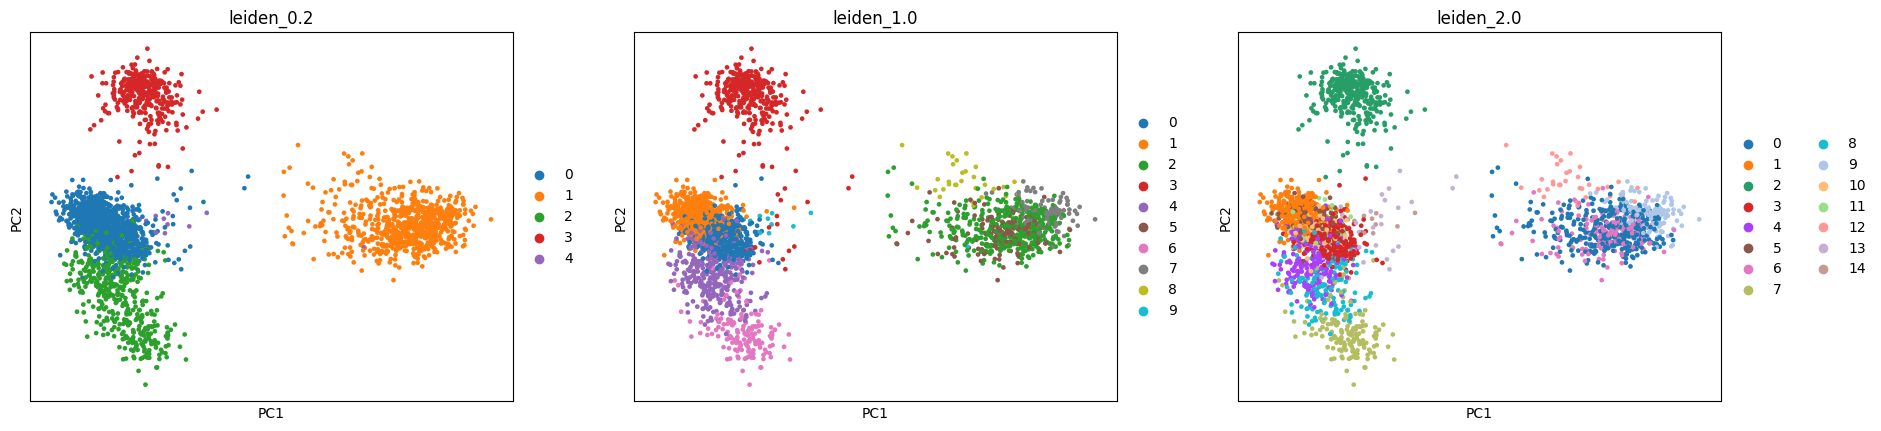

leiden_1.0
0    548
1    541
2    378
3    360
4    349
5    157
6    156
7    107
8     30
9     12
Name: count, dtype: int64


<Axes: xlabel='leiden_1.0'>

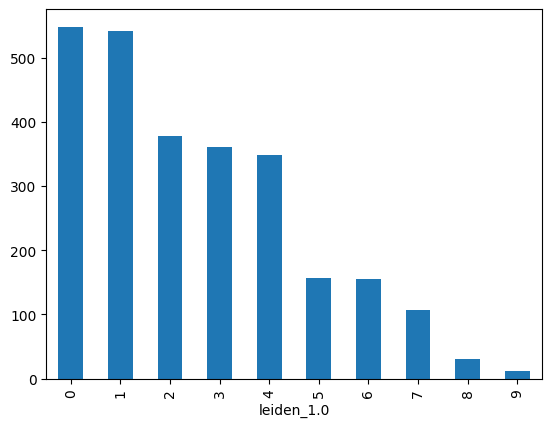

In [29]:
sc.tl.leiden(adata, resolution=0.2, key_added="leiden_0.2")
sc.tl.leiden(adata, resolution=1.0, key_added="leiden_1.0")
sc.tl.leiden(adata, resolution=2.0, key_added="leiden_2.0")

sc.pl.pca(
    adata,
    color=["leiden_0.2", "leiden_1.0", "leiden_2.0"],
    ncols=3
)
# Посмотрим, сколько получилось кластеров
print(adata.obs["leiden_1.0"].value_counts())
adata.obs["leiden_1.0"].value_counts().sort_index().plot.bar()

# 4. Переход из 30 измерений в два: t-SNE и UMAP

## 4.1. t-SNE: сохраняем вероятности соседства

Идея t-SNE: описать, насколько клетка $j$ является соседом клетки $i$, **вероятностью**, а затем подобрать на плоскости такую картинку, чтобы отношения соседства были похожими.

В высокоразмерном пространстве PCA условные вероятности определяются расстояниями:

$$
p_{j\mid i}=\frac{\exp\!\left(-\frac{\|\mathbf x_i-\mathbf x_j\|^2}{2\sigma_i^2}\right)}
{\sum_{k\ne i}\exp\!\left(-\frac{\|\mathbf x_i-\mathbf x_k\|^2}{2\sigma_i^2}\right)},\quad p_{i\mid i}=0.
$$

Далее строятся симметричные $p_{ij}=(p_{j\mid i}+p_{i\mid j})/(2n)$.

На двумерной карте используются тяжёлые хвосты распределения Стьюдента:

$$
q_{ij}=\frac{(1+\|\mathbf y_i-\mathbf y_j\|^2)^{-1}}
{\sum_{k\ne \ell}(1+\|\mathbf y_k-\mathbf y_\ell\|^2)^{-1}}.
$$

Подбираем координаты $\mathbf y_i$, минимизируя **KL-дивергенцию**:

$$
D_{\mathrm{KL}}(P\|Q)=\sum_{i\ne j}p_{ij}\log\frac{p_{ij}}{q_{ij}}.
$$

**Смысл:** большие $p_{ij}$ «требуют», чтобы на карте $q_{ij}$ тоже были большими. Тяжёлые хвосты помогают разнести точки, которые не являются соседями.

`perplexity` управляет эффективным масштабом локального соседства: $\operatorname{Perp}(P_i)=2^{H(P_i)}$, где энтропия считается с логарифмом по основанию 2. Это **не точное число соседей** и не число кластеров.

## 4.2. UMAP: сохраняем взвешенное локальное соседство

UMAP начинает с соседей, строит **взвешенный граф** локального соседства и ищет координаты $\mathbf y_i$ на плоскости, при которых локальные связи остаются похожими.

В упрощённой записи направленные веса близости оцениваются как

$$
w_{j\mid i}=\exp\left[-\frac{\max\{0,d(i,j)-\rho_i\}}{\sigma_i}\right],
$$

где $\rho_i$ — локальное расстояние до ближайшего ненулевого соседа, $\sigma_i$ — локальный масштаб. Вес может затем объединяться с обратным $w_{i\mid j}$ по правилу

$$
w_{ij}=w_{j\mid i}+w_{i\mid j}-w_{j\mid i}w_{i\mid j}.
$$

На плоскости близость приближается функцией вида

$$
\hat w_{ij}=\frac{1}{1+a\|\mathbf y_i-\mathbf y_j\|^{2b}},
$$

где $a,b$ зависят от настроек формы кривой. **Идея функции потерь** — кросс-энтропия между весами связей исходного графа и весами на плоскости:

$$
\mathcal L=-\sum_{i<j}\left[
 w_{ij}\log\hat w_{ij}+(1-w_{ij})\log(1-\hat w_{ij})\right].
$$

Реальная оптимизация использует приближения, включая отрицательное семплирование несоседних пар. Формула выше описывает **математическую цель**, а не буквальный полный перебор всех пар в каждой итерации.

Параметры:

- **`n_neighbors`** (в `sc.pp.neighbors`) определяет масштаб исходных локальных отношений.
- **`min_dist`** (в `sc.tl.umap`) регулирует, насколько плотно точки могут располагаться на карте.
- **`random_state`** задаёт воспроизводимый случайный старт/другие случайные шаги алгоритма.

## Полезно посмотреть
* https://github.com/NikolayOskolkov/HowUMAPWorks/blob/master/HowUMAPWorks.ipynb   
* https://pair-code.github.io/understanding-umap/

# 5.Leiden + UMAP + t-SNE

**Цель:** выполнить обе визуализации для **одних и тех же клеток и одних и тех же меток Leiden**. Только так можно корректно сравнивать полученные картинки.

`sc.tl.umap()` использует уже построенный граф соседства. `sc.tl.tsne()` ниже явно использует первые 30 PC.

In [30]:
sc.tl.umap(adata, min_dist=0.3, random_state=42)

sc.tl.tsne(adata, use_rep="X_pca", n_pcs=30, perplexity=30, random_state=42)

/tmp/ipykernel_1907/3859012779.py:3: FutureWarning: The argument use_rep is deprecated and will be removed in the future. Use `use` instead.
  sc.tl.tsne(adata, use_rep="X_pca", n_pcs=30, perplexity=30, random_state=42)


In [31]:
print("UMAP:", adata.obsm["X_umap"].shape,
      "t-SNE:", adata.obsm["X_tsne"].shape)

UMAP: (2638, 2) t-SNE: (2638, 2)


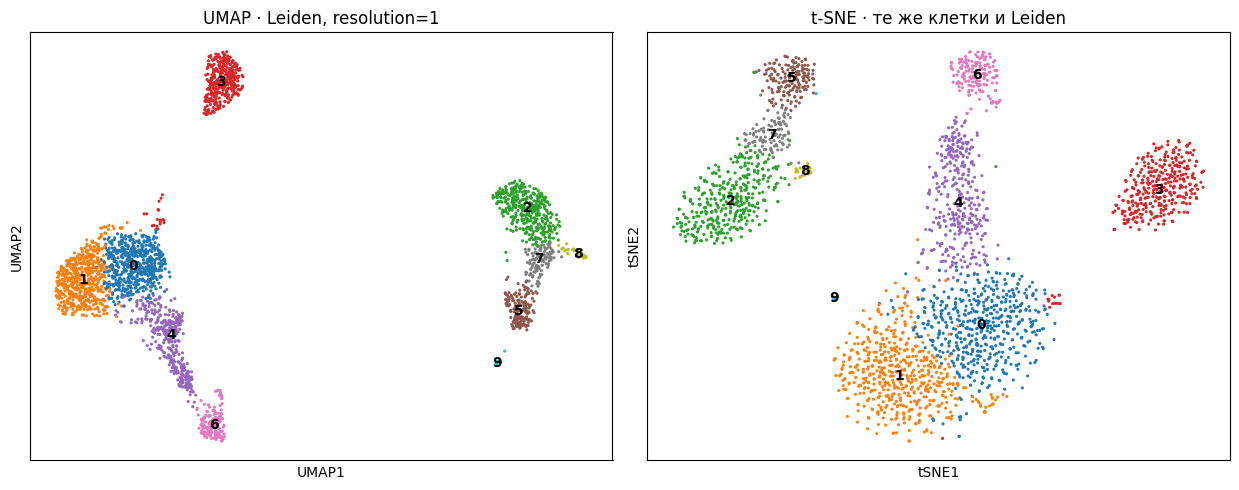

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.0))
sc.pl.umap(adata, color="leiden_1.0", legend_loc="on data",
           title="UMAP · Leiden, resolution=1", ax=axes[0], show=False, size=20)
sc.pl.tsne(adata, color="leiden_1.0", legend_loc="on data",
           title="t-SNE · те же клетки и Leiden", ax=axes[1], show=False, size=20)
plt.tight_layout()
plt.show()

## 5.1. Проверяем, что картинка не равна кластеризации

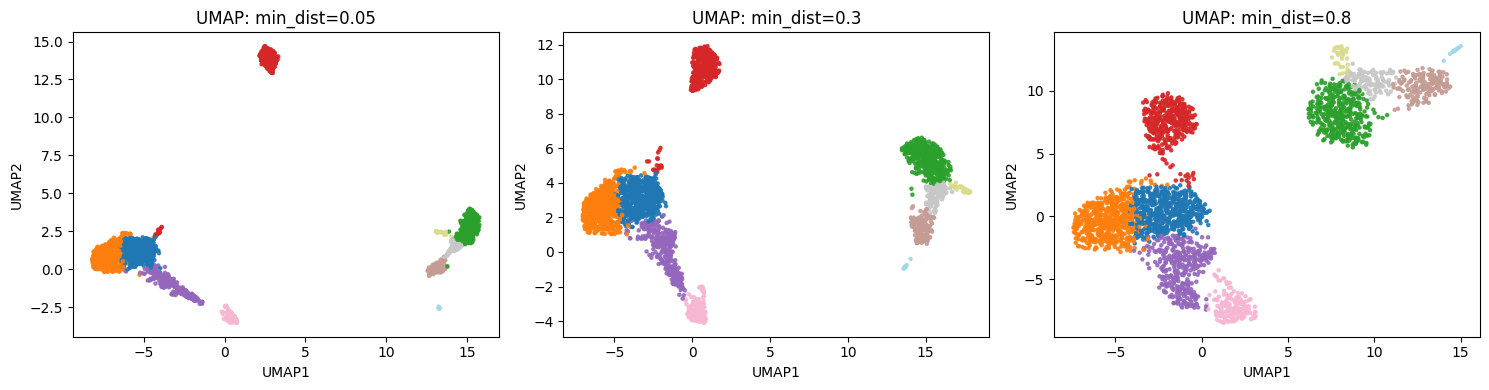

In [33]:
from copy import deepcopy
original_umap_params = deepcopy(adata.uns.get("umap", {}))
original_embedding = adata.obsm["X_umap"].copy()
original_labels = adata.obs["leiden_1.0"].copy()

embeddings = {0.3: original_embedding}
for value in (0.05, 0.8):
    sc.tl.umap(adata, min_dist=value, random_state=42)
    embeddings[value] = adata.obsm["X_umap"].copy()

adata.obsm["X_umap"] = original_embedding  # возвращаем основной UMAP
adata.uns["umap"] = original_umap_params  # и исходные параметры в AnnData
assert original_labels.equals(adata.obs["leiden_1.0"])

labels = adata.obs["leiden_1.0"].cat.codes.to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (value, xy) in zip(axes, sorted(embeddings.items())):
    ax.scatter(xy[:, 0], xy[:, 1], c=labels, cmap="tab20", s=5, alpha=0.85)
    ax.set(title=f"UMAP: min_dist={value}", xlabel="UMAP1", ylabel="UMAP2")
plt.tight_layout()
plt.show()

## 5.2. Проверка через биологию

Окрасим UMAP по известным генам-маркерам: `CD3D` (T-клетки), `MS4A1` (B-клетки), `NKG7` (NK-клетки), `LST1` (моноциты).

In [34]:
markers = [g for g in ["CD3D", "MS4A1", "NKG7", "LST1"] if g in adata.var_names]

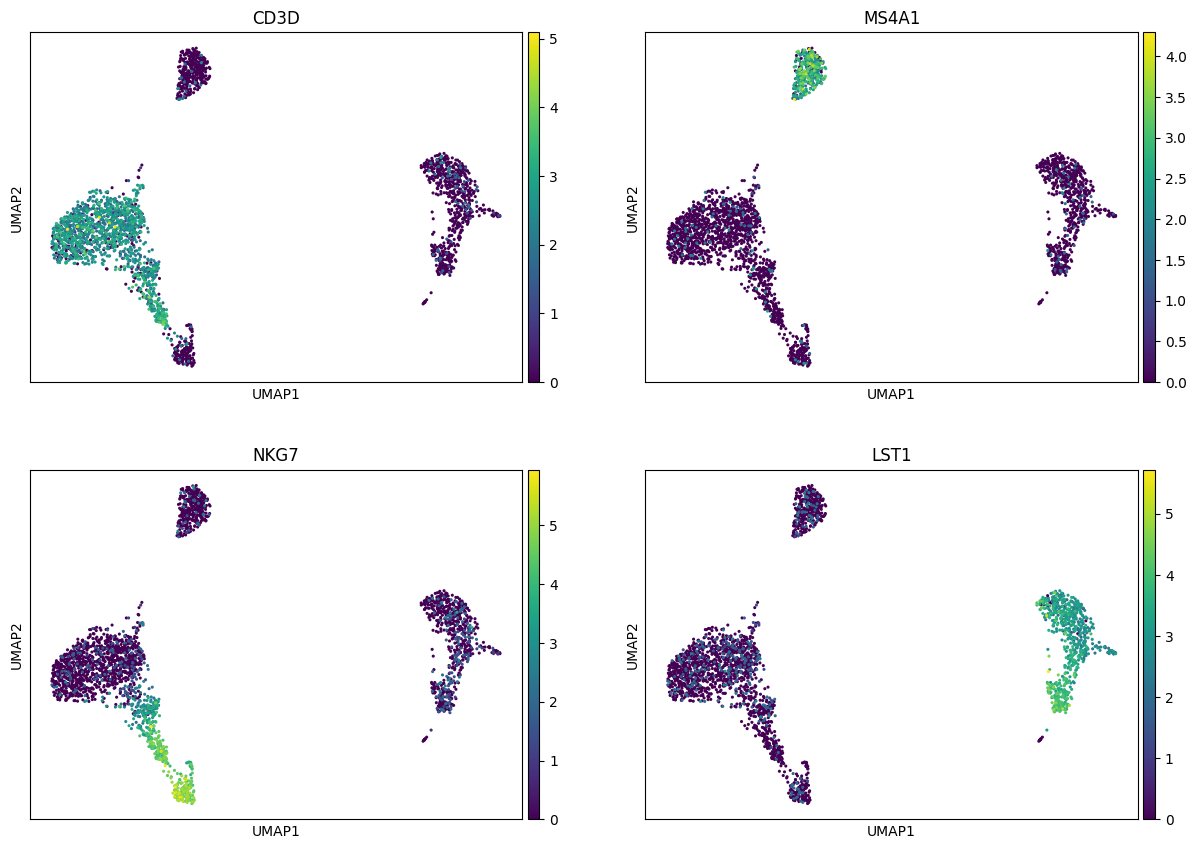

In [35]:
sc.pl.umap(adata, color=markers, ncols=2, size=20)

## 5.3. Сохраняем результаты для следующего занятия

В `.h5ad` сохраняются исходная матрица, `X_pca`, граф соседства, все варианты меток Leiden и основная визуализация `X_umap`/`X_tsne`. На следующем семинаре можно начать с аннотации кластеров, не повторяя вычисления.

In [36]:
result_path = Path("data/pbmc3k_after_clustering.h5ad")
adata.write_h5ad(result_path, compression="gzip")

# Самостоятельная работа: модулярность и анализ scRNA-seq

## Задание 1. Посчитать модулярность вручную

На рисунке показан **неориентированный невзвешенный граф из 9 вершин**. Рёбра внутри сообщества проведены сплошными линиями, между сообществами — пунктирными.

![Граф из 9 вершин](seminar6_modularity_graph.png)

Сообщества: **A = {1, 2, 3}**, **B = {4, 5, 6}**, **C = {7, 8, 9}**.

1. Посчитайте общее число рёбер графа `m`.
2. Для каждого сообщества найдите `l_c` — число рёбер, оба конца которых находятся внутри сообщества, и `d_c` — сумму степеней его вершин (включая внешние связи).
3. По формуле ниже вычислите **модулярность разбиения вручную**, показав промежуточные вычисления:

   $$Q=\sum_{c=1}^{3}\left(\frac{l_c}{m}-\left(\frac{d_c}{2m}\right)^2\right).$$

4. Объясните словами, зачем из доли внутренних рёбер вычитается второй член. Что показывает положительное значение `Q`? Является ли `Q` вероятностью?

## Задание 2. Самостоятельный анализ клеток в Scanpy

**Выберите один** набор 10x Genomics (PBMC 3k не использовать):

- [Клетки сердца эмбриона мыши E18 (~1011 клеток)](https://www.10xgenomics.com/datasets/1-k-heart-cells-from-an-e-18-mouse-v-3-chemistry-3-standard-3-0-0)
- [Клетки головного мозга эмбриона мыши E18 (~1301 клетка)](https://www.10xgenomics.com/datasets/1-k-brain-cells-from-an-e-18-mouse-v-3-chemistry-3-standard-3-0-0)
- [Клетки селезёнки мыши (~1119 клеток)](https://www.10xgenomics.com/datasets/splenocytes-from-c-57-bl-6-mice-1-k-cells-v-2-2-standard-4-0-0)

На странице набора загрузите **Feature / cell matrix HDF5 (filtered)** (для селезёнки — матрицу **Gene Expression**, а не V(D)J). Это счётчики UMI для баркодов, уже отобранных Cell Ranger; исходные пустые капли в эту матрицу не входят.

```python
import scanpy as sc
adata = sc.read_10x_h5("путь/к/скачанному_файлу.h5")
adata.var_names_make_unique()
```

**Проведите анализ**, используя методы Scanpy, изученные на семинарах:

1. **QC.** Посчитайте и покажите распределения количества UMI (`total_counts`), обнаруженных генов (`n_genes_by_counts`) и доли митохондриальных счётчиков (`pct_counts_mt`). Выберите пороги фильтрации клеток и генов, примените их и **объясните почему выбрали именно эти значения**. Укажите, сколько клеток осталось.
2. **Нормализация и HVG.** Выполните нормализацию, `log1p` и отбор высоковариабельных генов. Укажите число HVG и объясните, зачем их отбирают и почему выбранное количество разумно.
3. **PCA.** Постройте PCA. Выберите число главных компонент для дальнейшего анализа; объясните выбор, используя график доли объяснённой дисперсии.
4. **Граф и Leiden.** Постройте граф соседей, выполните кластеризацию Leiden. Укажите `n_neighbors`, `n_pcs`, `resolution`, число получившихся кластеров и число клеток в них. Объясните выбранные параметры.
5. **UMAP и t-SNE.** Постройте обе визуализации, раскрасив точки по меткам Leiden. Также раскрасьте PCA или UMAP по одной QC-метрике и по **двум выбранным известным генам**, если они есть в данных. Опишите, что видно и какие выводы сделать нельзя.
6. **Биологический вывод.** По нескольким предложениям объясните, какие клеточные популяции **предположительно** присутствуют в выбранной ткани. Обоснуйте предположение экспрессией выбранных генов; не называйте кластеры достоверно определёнными клеточными типами.

**Разрешено:** стандартные функции Scanpy для QC, фильтрации, нормализации, HVG, PCA, графа соседей, Leiden, UMAP и t-SNE; окраска графиков по кластерам, QC-метрикам и **заданным вручную** генам.

**Не использовать:** `sc.tl.rank_genes_groups`, `sc.tl.score_genes`, методы автоматической аннотации или другие ещё не изученные методы. Подбор генов можно сделать по литературе, без автоматического поиска маркеров.

**Что сдавать:** число и расчёт модулярности; Jupyter-ноутбук с анализом одного набора данных, графиками, числом клеток до/после QC, параметрами и краткими объяснениями сделанных решений. Не требуется получить «правильное» число кластеров.


### Решение Задания 1

**1. Общее число рёбер \(m\):**
Граф неориентированный. Считаем по картинке: \(m = 12\).

**2. Для каждого сообщества:**
*   **A = {1, 2, 3}**:
    *   \(l_A = 3\) (рёбра: 1-2, 2-3, 1-3)
    *   Степени вершин: 1 (3), 2 (4), 3 (4). Сумма \(d_A = 3+4+4 = 11\)
*   **B = {4, 5, 6}**:
    *   \(l_B = 3\) (рёбра: 4-5, 5-6, 4-6)
    *   Степени вершин: 4 (4), 5 (3), 6 (3). Сумма \(d_B = 4+3+3 = 10\)
*   **C = {7, 8, 9}**:
    *   \(l_C = 3\) (рёбра: 7-8, 8-9, 7-9)
    *   Степени вершин: 7 (3), 8 (4), 9 (4). Сумма \(d_C = 3+4+4 = 11\)

*(Сумма степеней всех вершин: \(11 + 10 + 11 = 32\). Значит, \(2m = 32\), \(m = 16\). Если у тебя на картинке другие линии, просто пересчитай \(l_C\) и \(d_C\) по аналогии).*

**3. Модулярность Q:**
\(Q = \sum (l_c/m - (d_c/2m)^2) = (3/16 - (11/32)^2) + (3/16 - (10/32)^2) + (3/16 - (11/32)^2) = \dots\) *(подставь свои числа)*.

**4. Объяснение:**
Второй член \((d_c/2m)^2\) — это ожидаемая доля рёбер внутри сообщества, если бы рёбра были распределены случайно (модель случайного графа). Вычитая его, мы смотрим, насколько сообщество *сильнее связано внутри*, чем ожидалось бы случайно. Положительное \(Q\) означает, что структура не случайна. \(Q\) — это не вероятность, а статистика качества разбиения (обычно от -0.5 до 1).

## Задание 2. Самостоятельный анализ (датасет мыши)
Выбранный датасет: (напиши, какой выбрала, например, "Клетки сердца эмбриона мыши E18")

In [39]:
!wget https://cf.10xgenomics.com/samples/cell-exp/1.1.0/E18_mouse_heart/E18_mouse_heart_filtered_gene_bc_matrices_h5.h5 -O mouse_heart.h5

adata_mouse = sc.read_10x_h5("heart_1k_v2_filtered_feature_bc_matrix.h5")
adata_mouse.var_names_make_unique()

--2026-11-21 14:11:52--  https://cf.10xgenomics.com/samples/cell-exp/1.1.0/E18_mouse_heart/E18_mouse_heart_filtered_gene_bc_matrices_h5.h5
Resolving cf.10xgenomics.com (cf.10xgenomics.com)... 104.18.1.173, 104.18.0.173, 2606:4700::6812:ad, ...
Connecting to cf.10xgenomics.com (cf.10xgenomics.com)|104.18.1.173|:443... connected.
HTTP request sent, awaiting response... 403 Forbidden
2026-11-21 14:11:52 ERROR 403: Forbidden.



/tmp/ipykernel_1907/2449480005.py:3: FutureWarning: Import from `scanpy.io` instead
  adata_mouse = sc.read_10x_h5("heart_1k_v2_filtered_feature_bc_matrix.h5")
/usr/local/lib/python3.13/dist-packages/scanpy/io/_read.py:229: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


### 1. QC. Расчет метрик и фильтрация

/tmp/ipykernel_1907/519232657.py:2: FutureWarning: The argument inplace is deprecated and will be removed in the future. Use `out=False` instead of `inplace=True`.
  sc.pp.calculate_qc_metrics(adata_mouse, qc_vars=["mt"], inplace=True)


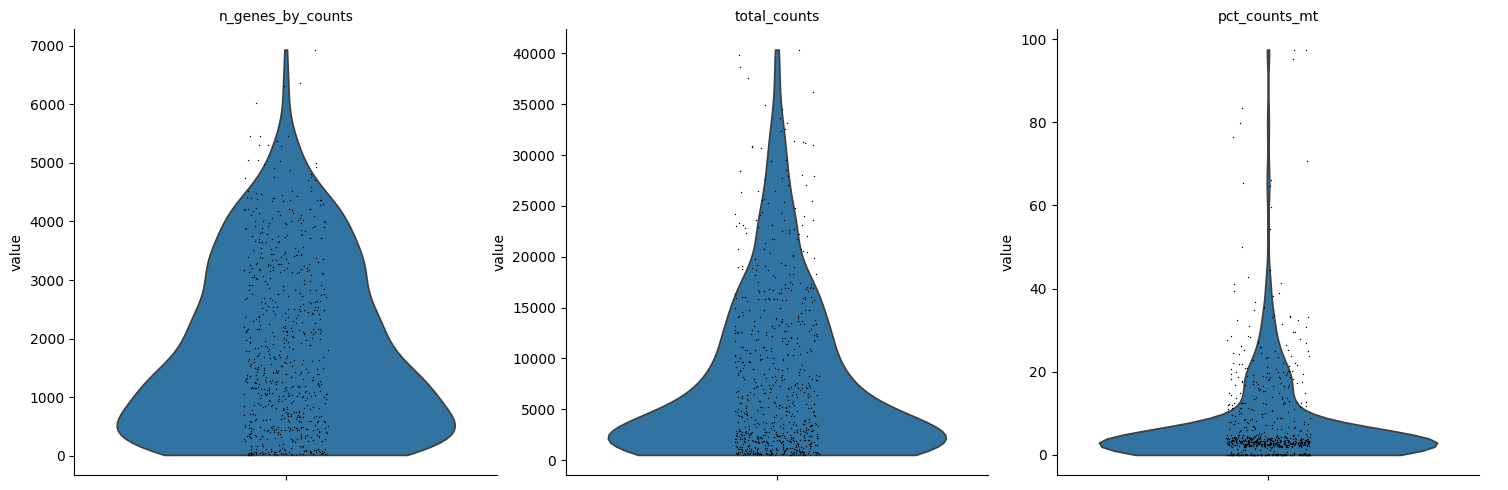

In [40]:
adata_mouse.var["mt"] = adata_mouse.var_names.str.startswith("mt-")
sc.pp.calculate_qc_metrics(adata_mouse, qc_vars=["mt"], inplace=True)

sc.pl.violin(adata_mouse, ["n_genes_by_counts", "total_counts", "pct_counts_mt"], multi_panel=True)


sc.pp.filter_cells(adata_mouse, min_genes=200)
sc.pp.filter_genes(adata_mouse, min_cells=3)


### 2. Нормализация и HVG

/tmp/ipykernel_1907/3407389096.py:4: FutureWarning: The argument layer is deprecated and will be removed in the future. Use `use` instead.
  sc.pp.highly_variable_genes(adata_mouse, n_top_genes=2000, flavor="seurat_v3", layer="counts")


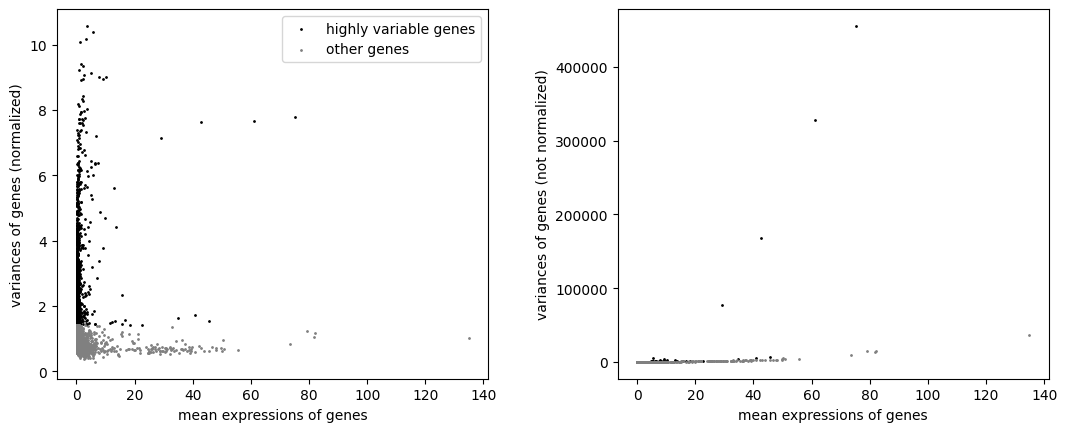

In [41]:
adata_mouse.layers["counts"] = adata_mouse.X.copy()
sc.pp.normalize_total(adata_mouse, target_sum=1e4)
sc.pp.log1p(adata_mouse)
sc.pp.highly_variable_genes(adata_mouse, n_top_genes=2000, flavor="seurat_v3", layer="counts")
sc.pl.highly_variable_genes(adata_mouse)

### 3. PCA

/tmp/ipykernel_1907/1147974475.py:1: FutureWarning: The argument mask_var is deprecated and will be removed in the future. Use `mask` instead.
  sc.tl.pca(adata_mouse, n_comps=50, mask_var="highly_variable")


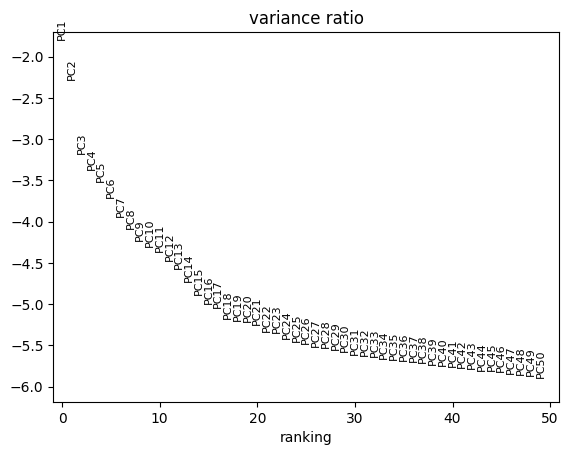

In [42]:
sc.tl.pca(adata_mouse, n_comps=50, mask_var="highly_variable")
sc.pl.pca_variance_ratio(adata_mouse, n_pcs=50, log=True)

### 4. Граф и Leiden

/tmp/ipykernel_1907/1902322187.py:2: FutureWarning: The argument key_added is deprecated and will be removed in the future. Use `out` instead.
  sc.tl.leiden(adata_mouse, resolution=1.0, key_added="leiden", flavor="igraph", n_iterations=2, directed=False)


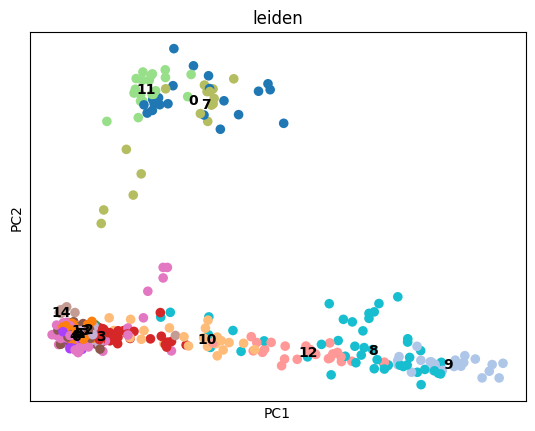

In [43]:
sc.pp.neighbors(adata_mouse, n_neighbors=15, n_pcs=30)
sc.tl.leiden(adata_mouse, resolution=1.0, key_added="leiden", flavor="igraph", n_iterations=2, directed=False)
sc.pl.pca(adata_mouse, color="leiden", legend_loc="on data")

### 5. UMAP / t-SNE

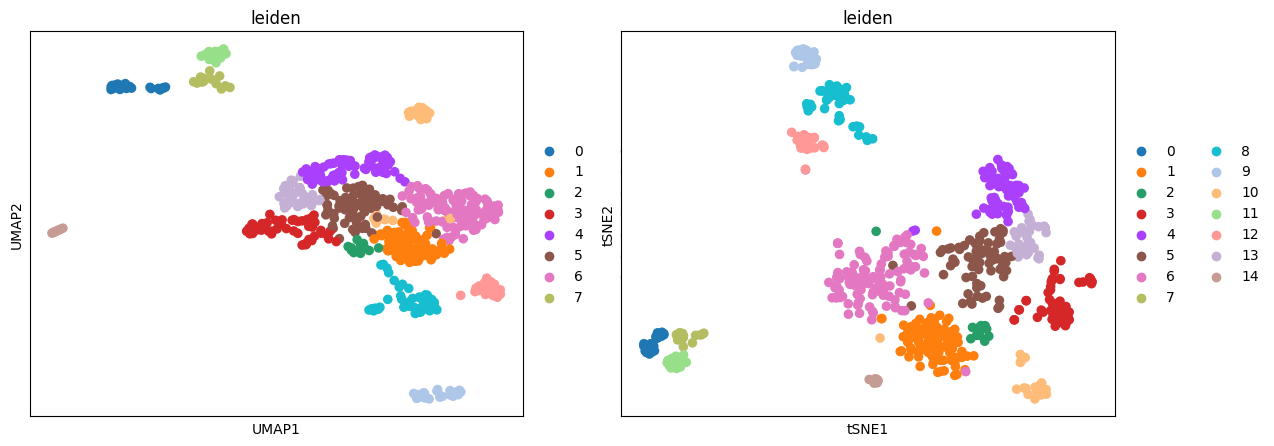

In [44]:
sc.tl.umap(adata_mouse, random_state=42)
sc.tl.tsne(adata_mouse, n_pcs=30, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sc.pl.umap(adata_mouse, color="leiden", ax=axes[0], show=False)
sc.pl.tsne(adata_mouse, color="leiden", ax=axes[1], show=False)
plt.show()

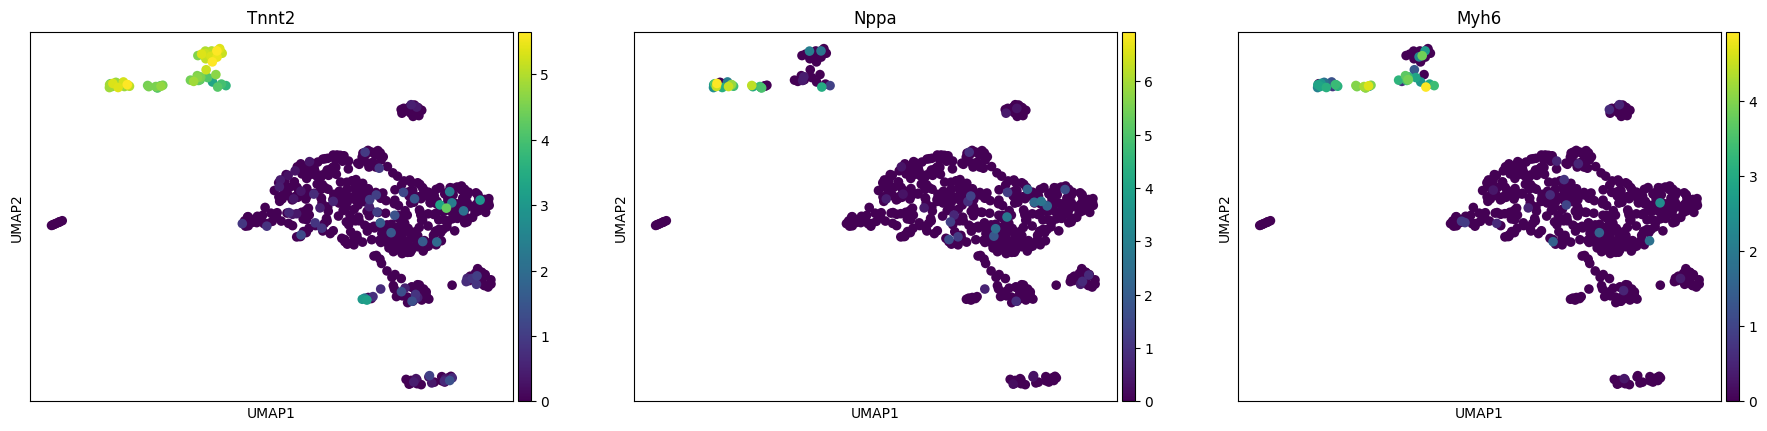

In [45]:
known_markers = ["Tnnt2", "Nppa", "Myh6"]
known_markers = [g for g in known_markers if g in adata_mouse.var_names]

sc.pl.umap(adata_mouse, color=known_markers, ncols=len(known_markers))

In [12]:
mouse =

SyntaxError: invalid syntax (2216321927.py, line 1)